# Late Noodles: Charting Continuous Data
SDEV2501 · Day 14 · **Finished notebook**

The owner of a (fictional) noodle shop on Whyte Ave sends over September's delivery records with one line attached: *"People keep saying our delivery is slow. Can you look into it?"*

That's a fair question, but no chart can answer it as it stands. Slow compared to what? Slow for everyone, or only for some customers? And if some orders are slow, why? A big part of the job is turning a vague question like this into specific ones that a chart can answer. We'll ask three:

1. How long does a delivery usually take? That's a **histogram**.
2. Is it slower in some neighbourhoods than in others? That's a **box plot**.
3. Does distance explain the slow ones? That's a **scatter plot**.

At the end you'll put the three answers together into a reply you could actually send the owner.

The data is in `deliveries_sept.csv`, 300 orders from September 2026. Every number in it is made up, but the shapes behave like the real thing.

## 0. Setup
Run this cell to import the libraries.

In [1]:
# pandas: tables. matplotlib.pyplot: drawing. Same nicknames as always.
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the CSV and take a quick look
Before you chart anything, find out what you've got: how many rows, what the columns are, and roughly what values they hold.

Load `deliveries_sept.csv` into a DataFrame called `deliveries` (turn `order_time` into real dates), then show its shape, the first few rows and a summary of the number columns.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(..., parse_dates=[...])` | Loads the CSV into a DataFrame and turns the listed columns into real dates. |
| `.shape` | The number of rows and columns. It's an attribute, so no brackets. |
| `head()` | Shows the first five rows. |
| `describe()` | Summarizes every number column: count, mean, quartiles and so on. |

In [2]:
# ---------------------------------------------------------------
# LOAD + INSPECT
# ---------------------------------------------------------------
# parse_dates turns the order_time text into real datetimes.
deliveries = pd.read_csv("deliveries_sept.csv", parse_dates=["order_time"])

# (rows, columns): expect (300, 8)
print(deliveries.shape)

# head() returns a DataFrame; display() shows it as a table mid-cell
# (only the LAST line of a cell is displayed automatically).
display(deliveries.head())

# Summary of every number column. Read the delivery_min row: mean vs median (50%).
deliveries.describe()

(300, 8)


,order_id,order_time,zone,distance_km,delivery_min,order_total,tip,rating
0,8001,2026-09-01 11:38:00,Downtown,4.3,30,20.93,0.43,4
1,8002,2026-09-01 11:41:00,Downtown,2.4,17,72.49,6.09,5
2,8003,2026-09-01 13:52:00,Downtown,3.9,30,23.35,1.97,5
3,8004,2026-09-01 14:00:00,Westmount,6.1,28,86.01,13.26,4
4,8005,2026-09-01 14:01:00,Downtown,3.3,22,14.03,0.94,5


,order_id,order_time,distance_km,delivery_min,order_total,tip,rating
count,300.000000,300,300.000000,300.000000,300.000000,300.000000,300.000000
mean,8150.500000,2026-09-16 16:35:32,4.708333,29.026667,40.303900,4.126733,4.076667
min,8001.000000,2026-09-01 11:38:00,0.500000,14.000000,9.000000,0.000000,1.000000
25%,8075.750000,2026-09-08 19:23:00,2.300000,21.000000,20.735000,1.815000,4.000000
50%,8150.500000,2026-09-16 14:29:30,3.600000,26.000000,27.455000,3.140000,4.000000
75%,8225.250000,2026-09-24 15:11:30,5.800000,32.000000,62.922500,5.812500,5.000000
max,8300.000000,2026-09-30 20:41:00,13.900000,101.000000,89.390000,16.080000,5.000000
std,86.746758,NaN,3.594156,12.712381,23.741033,3.455849,1.016974


Explain which columns are **continuous**, which are **discrete** (counts or categories), which one is **ordinal** (ordered categories), and which number is just a **label**. `delivery_min` is recorded in whole minutes, so explain whether that makes it discrete too (the slide on continuous data vs continuous distributions has the answer).

*Answer:*

`distance_km`, `delivery_min`, `order_total` and `tip` are continuous. (Money is technically counted in cents, but there are so many possible values that we treat it as continuous.) `order_time` is continuous time too.

`zone` is discrete: four neighbourhoods. `rating` is ordinal, because 1 to 5 are ordered categories, like the customer-satisfaction row in today's data-types table. `order_id` is a label. It's stored as a number, but adding or averaging order IDs means nothing.

Whole minutes don't make `delivery_min` discrete. It's still a measurement of time; it was just recorded to the nearest minute, like height recorded as 172 cm.

## 2. A basic histogram
Start with the plainest version of "is it slow?": *how long does a delivery usually take?* That's one continuous column, and we want to see its whole distribution, so it's a histogram.

Draw a histogram of `delivery_min` with nothing but the defaults. Then draw it again with 20 bins, a title and both axis labels.

| You'll need | What it's for |
|---|---|
| `plt.hist(...)` | Draws a histogram of one column, with 10 bins unless you say otherwise. |
| `plt.hist(..., bins=...)` | Sets how many equal-width bins to split the values into. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels. |
| `plt.show()` | Displays the chart. |

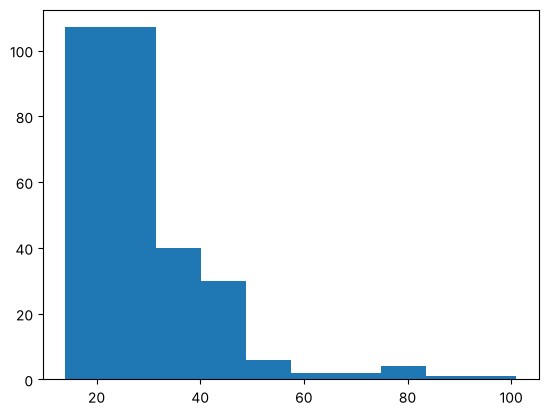

In [3]:
# ---------------------------------------------------------------
# HISTOGRAM, ALL DEFAULTS
# ---------------------------------------------------------------
# plt.hist draws on the "current" chart (it makes one if there isn't one).
# Default: 10 equal-width bins between the smallest and largest value.
plt.hist(deliveries["delivery_min"])
plt.show()

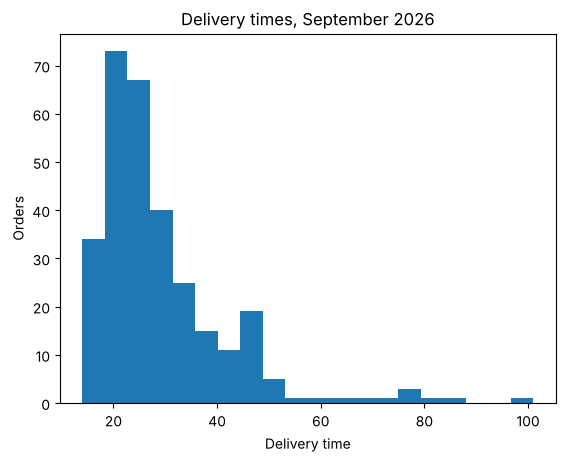

In [4]:
# ---------------------------------------------------------------
# HISTOGRAM WITH BINS, TITLE AND LABELS
# ---------------------------------------------------------------
# bins=20 -> twenty equal-width ranges between the min (14) and max (101).
plt.hist(deliveries["delivery_min"], bins=20)

# Every chart gets a title and labels that say what the axes mean.
plt.title("Delivery times, September 2026")
plt.xlabel("Delivery time")
plt.ylabel("Orders")
plt.show()

## 3. Improve it: bin width, size, colour, units
With `bins=20`, matplotlib splits the range from the fastest delivery (14 minutes) to the slowest (101 minutes) into 20 equal bars, each 4.35 minutes wide. The bars are correct, but their boundaries land on values like 18.35 and 22.7, which makes the chart hard to read.

You can choose the boundaries yourself by giving `bins=` a list of **bin edges** instead of a count. The edges are the points where one bar ends and the next begins. For example, the edges 10, 15, 20 and 25 make three bars: 10 to 15 minutes, 15 to 20 and 20 to 25. Any value outside the first and last edge isn't counted at all.

Redraw the histogram with:
- 5-minute bins from 10 to 105 minutes,
- a wider figure (8 × 4 inches),
- a single colour of your choice,
- units in the axis labels.

| You'll need | What it's for |
|---|---|
| `plt.figure(figsize=...)` | Starts a new chart at a set size in inches (width, height). Call it before you draw. |
| `plt.hist(..., bins=..., color=...)` | Draws the histogram. `bins` can be a list of bin edges instead of a count, and `color` sets one colour for every bar. |
| `range(start, stop, step)` | Builds the list of bin edges. It stops *before* `stop`. |
| `plt.xlabel()`, `plt.ylabel()` | The axis labels. Put the units in brackets. |

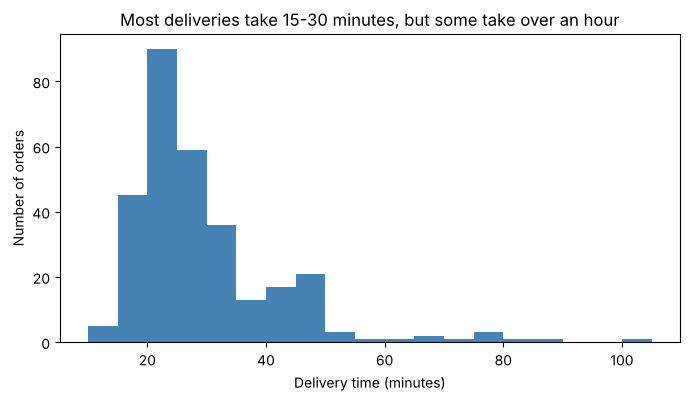

In [5]:
# ---------------------------------------------------------------
# HISTOGRAM, IMPROVED
# ---------------------------------------------------------------
# A new, wider chart: 8 inches wide, 4 tall.
plt.figure(figsize=(8, 4))

# bins = a list of EDGES this time: 10, 15, 20, ..., 105.
# range stops before its end value, so range(10, 110, 5) ends at 105
# and the 101-minute order still gets a bin.
plt.hist(deliveries["delivery_min"], bins=range(10, 110, 5), color="steelblue")

plt.title("Most deliveries take 15-30 minutes, but some take over an hour")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.show()

## 4. Box plot: is it slow everywhere?
A box plot summarizes a column in five numbers. The **box** runs from Q1 (25th percentile) to Q3 (75th), so it holds the middle 50% of orders. The **line inside** is the median. The **whiskers** reach out to the furthest value that's still within 1.5 × IQR of the box (matplotlib's default), and anything further out is drawn as a dot: a *potential* outlier.

Draw a box plot of `delivery_min` on its own, with a title and a y-axis label. Then print Q1, the median and Q3 and check they match the box.

| You'll need | What it's for |
|---|---|
| `plt.boxplot(...)` | Draws a box plot of one column. |
| `plt.title()`, `plt.ylabel()` | The chart title and the y-axis label. |
| `quantile([...])` | Returns the values at the percentiles you list, written as fractions (0.5 is the median). |

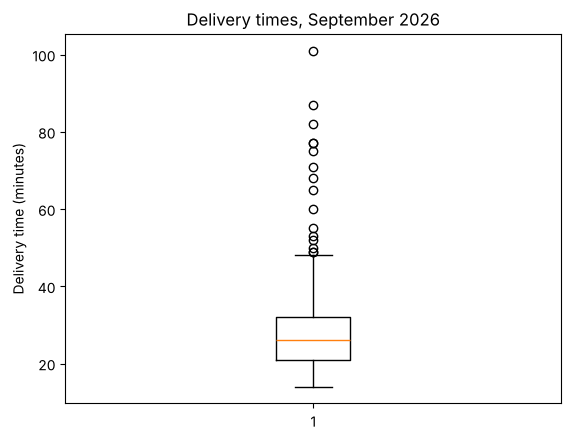

0.25    21.0
0.50    26.0
0.75    32.0
Name: delivery_min, dtype: float64
IQR: 11.0   upper whisker limit (Q3 + 1.5 x IQR): 48.5


In [6]:
# ---------------------------------------------------------------
# ONE BOX PLOT
# ---------------------------------------------------------------
plt.boxplot(deliveries["delivery_min"])
plt.title("Delivery times, September 2026")
plt.ylabel("Delivery time (minutes)")
plt.show()

# The three numbers the box is built from.
q = deliveries["delivery_min"].quantile([0.25, 0.5, 0.75])
iqr = q[0.75] - q[0.25]
print(q)
print("IQR:", iqr, "  upper whisker limit (Q3 + 1.5 x IQR):", q[0.75] + 1.5 * iqr)

A single box summarizes every order at once. Box plots are most useful side by side, one per group, which is the question on the box plot slide: *how do groups compare?* For the owner, that's the second question: is delivery slow everywhere, or only in some neighbourhoods?

Draw one box per `zone`, in this order: Old Strathcona, Downtown, Westmount, Mill Woods (closest to the shop first). Label each box with its zone.

| You'll need | What it's for |
|---|---|
| a list of zone names | Sets which boxes appear and in what order. |
| a list comprehension with a boolean mask | Builds one Series of delivery times per zone. |
| `plt.boxplot(..., tick_labels=...)` | Given a list of Series, draws one box per Series. `tick_labels` names each box. |

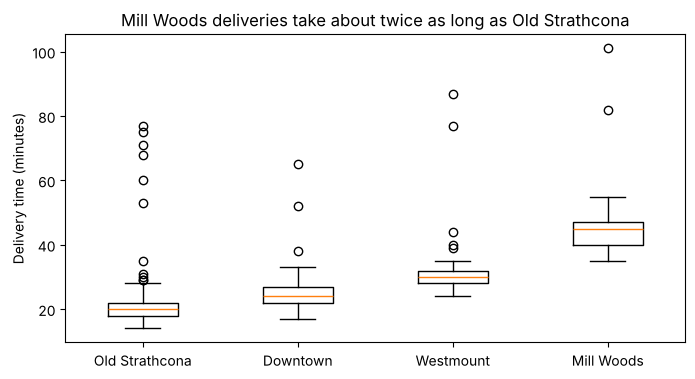

zone
Downtown          24.0
Mill Woods        45.0
Old Strathcona    20.0
Westmount         30.0
Name: delivery_min, dtype: float64

In [7]:
# ---------------------------------------------------------------
# BOX PLOT BY ZONE
# ---------------------------------------------------------------
# Order matters: closest to the shop on the left, furthest on the right.
zones = ["Old Strathcona", "Downtown", "Westmount", "Mill Woods"]

# One Series of delivery times per zone, built with a list comprehension:
#   for each zone z, keep the rows where zone == z, take delivery_min.
groups = [deliveries.loc[deliveries["zone"] == z, "delivery_min"] for z in zones]

plt.figure(figsize=(8, 4))
# A LIST of Series -> one box per Series. tick_labels names them.
plt.boxplot(groups, tick_labels=zones)
plt.title("Mill Woods deliveries take about twice as long as Old Strathcona")
plt.ylabel("Delivery time (minutes)")
plt.show()

# The medians, to check the title's claim.
deliveries.groupby("zone")["delivery_min"].median()

Explain what your box plots show by answering these three questions. Read the answers off the charts, then check them against the numbers the code printed.

1. In the single box plot, what do the line inside the box, the bottom and top of the box, and the ends of the whiskers each tell you about delivery times? Put each one in a sentence with its number of minutes.
2. In the box plot by zone, which neighbourhood is slowest? Which has the most dots, and are those dots mistakes?
3. Compare the box plot with your histogram from §3. Name one thing the box plot makes easier to see, and one thing only the histogram shows.

*Answer:*

1. The line inside the box is the median, 26 minutes, so half of all deliveries took 26 minutes or less. The box runs from Q1 (21 minutes) to Q3 (32 minutes), which means the middle half of deliveries took between 21 and 32 minutes and the IQR is 11 minutes. The bottom whisker ends at the fastest delivery, 14 minutes. The top whisker stops at 48 minutes, the longest delivery that's still within 1.5 × IQR of the box (48.5 minutes). The 16 dots above it are everything longer, up to 101 minutes.
2. Mill Woods is slowest, with a median of 45 minutes, more than double Old Strathcona's 20. That makes sense, because it's the furthest away. Old Strathcona has the most dots (11), with deliveries up to 77 minutes. They aren't mistakes. They're real orders that went badly, and they're probably the most interesting rows in the file. A dot means "unusual", not "wrong".
3. The box plot makes it much easier to **compare groups** side by side and to pick out the median and the outliers. Only the histogram shows the **shape**: the peak at 20-30 minutes, the long right tail, and a second little bump at 40-50 minutes (which the zone box plot reveals is Mill Woods).

## 5. Scatter plot: does distance explain it?
The box plot showed the neighbourhoods furthest from the shop are the slowest, which raises the third question: *do longer trips simply take longer?* That's two continuous columns, so we draw one dot per order, with distance on x and time on y.

Draw a scatter plot of `delivery_min` against `distance_km`, with a title and labelled axes (units!).

| You'll need | What it's for |
|---|---|
| `plt.scatter(x, y)` | Draws one dot per row, with `x` across and `y` up. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels, with units. |

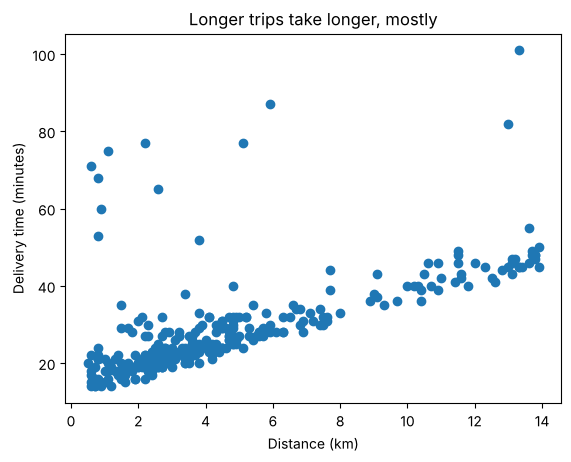

np.float64(0.6276909465207527)

In [8]:
# ---------------------------------------------------------------
# SCATTER: distance vs delivery time
# ---------------------------------------------------------------
# x = what we think explains it (distance), y = what we're explaining (time).
plt.scatter(deliveries["distance_km"], deliveries["delivery_min"])
plt.title("Longer trips take longer, mostly")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

# corr() = correlation, -1 to 1. Near 1 = strong upward trend.
deliveries["distance_km"].corr(deliveries["delivery_min"])

Most dots follow the trend, but a few float way above it. Those are the orders the owner actually cares about. Colour can pick them out: grey for the ordinary orders, one strong colour for the late ones, and a legend so the colour isn't the *only* way to tell them apart.

Call any order over 45 minutes "late". Draw the on-time orders in light grey and the late orders in a strong colour, each with a label, and add a legend.

| You'll need | What it's for |
|---|---|
| `deliveries[... > 45]`, `deliveries[... <= 45]` | Filters the DataFrame down to the rows that match a condition, once for late orders and once for the rest. |
| `plt.scatter(x, y, color=..., label=...)` | Called twice, it draws two sets of dots on the same chart, each with its own colour and legend name. |
| `plt.legend()` | Adds a key built from the `label`s. |

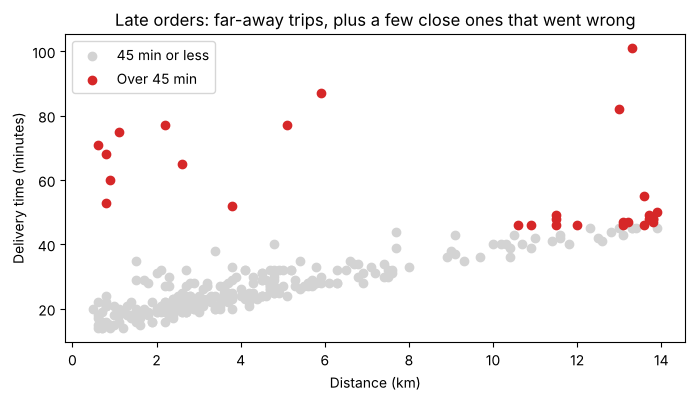

late orders: 29


In [9]:
# ---------------------------------------------------------------
# SCATTER WITH COLOUR THAT MEANS SOMETHING
# ---------------------------------------------------------------
# Two filters: the late orders, and everything else.
late = deliveries[deliveries["delivery_min"] > 45]
on_time = deliveries[deliveries["delivery_min"] <= 45]

plt.figure(figsize=(8, 4))
# Neutral base first, then the colour that carries the message.
plt.scatter(on_time["distance_km"], on_time["delivery_min"], color="lightgrey", label="45 min or less")
plt.scatter(late["distance_km"], late["delivery_min"], color="tab:red", label="Over 45 min")

# A legend so colour isn't the only clue.
plt.legend()
plt.title("Late orders: far-away trips, plus a few close ones that went wrong")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

# len() of a DataFrame is its number of rows.
print("late orders:", len(late))

## 6. What each chart can't tell you
Every chart hides something. Fill in the last column from what you saw today.

| Chart | Question it answered | What it hides or gets wrong |
|---|---|---|
| Histogram | How long do deliveries usually take? | The shape changes with the bins you pick. Hard to compare groups. Says nothing about *why*. |
| Box plot | Do neighbourhoods differ? | Hides the shape (two humps look like one box). Doesn't show how many orders are in each box: Mill Woods has 48, Old Strathcona 97. |
| Scatter plot | Does distance explain delivery time? | Shows that two things move together, not that one causes the other. Dots pile on top of each other with lots of data. Only two variables at a time unless you add colour. |

## 7. Back to the owner
The owner asked a vague question: *"People keep saying our delivery is slow. Can you look into it?"* You've now answered three specific ones.

Explain, in four or five sentences you could send the owner, whether deliveries really are slow and what's behind the slow ones. Use numbers from your charts, and keep it in plain language: the owner doesn't know what an IQR is.

*Answer:*

Most deliveries aren't slow: half arrive within 26 minutes, and the middle half take between 21 and 32. Mill Woods orders take about 45 minutes, more than double Old Strathcona's 20, but that's distance, since Mill Woods is 9 to 14 km away, so it's a decision about delivery fees or promised times rather than a kitchen problem. The orders worth chasing are seven trips of under 3 km that took between 53 and 77 minutes, six of them in Old Strathcona, because distance can't explain those. They're probably the ones people are complaining about. The next step is to find out what happened to them: the time of day, the driver, or a backed-up kitchen.

## 8. Individual practice
The owner liked your answer and comes back with another vague one, this time about money: *"Are we doing OK on orders and tips?"* Turn it into two specific questions, one about a *distribution* and one about a *relationship*, and answer each with a **different type of chart**.

Here are some questions to start from, or write your own:
- *What does a typical order total look like?*
- *Do bigger orders get bigger tips?*
- *Does tip depend on delivery time?*
- *How do customers rate us?* (Careful: check the data-types table from today's slides for what kind of data `rating` is before you choose a chart.)

For each chart, write the question as a Markdown heading first, then the code, then one sentence on what the chart shows. Use what you did today: bins you chose on purpose, units on the axes, a title that states the finding, and colour only where it has a job.

### Example 1 (distribution): what does a typical order total look like?

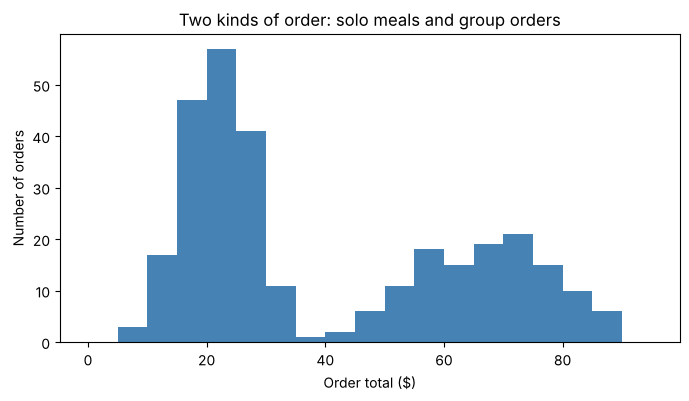

mean 40.3   median 27.455


In [10]:
# ---------------------------------------------------------------
# PRACTICE 1 (distribution): what does a typical order total look like?
# ---------------------------------------------------------------
plt.figure(figsize=(8, 4))
plt.hist(deliveries["order_total"], bins=range(0, 100, 5), color="steelblue")
plt.title("Two kinds of order: solo meals and group orders")
plt.xlabel("Order total ($)")
plt.ylabel("Number of orders")
plt.show()

print("mean", round(deliveries["order_total"].mean(), 2), "  median", deliveries["order_total"].median())

There are two kinds of order, solo meals around \$20 and group orders around \$65, with almost nothing in between. The mean (\$40.30) lands in that gap, so "the average order" is an order hardly anyone places. A box plot of this column would draw one tidy box and hide both humps.

### Example 2 (relationship): do bigger orders get bigger tips?

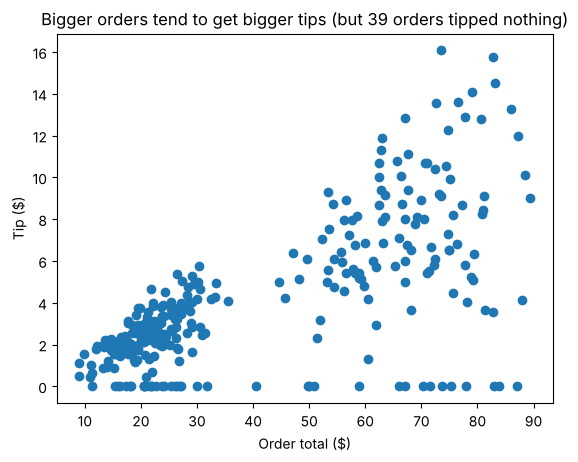

corr 0.68
zero tips: 39


In [11]:
# ---------------------------------------------------------------
# PRACTICE 2 (relationship): do bigger orders get bigger tips?
# ---------------------------------------------------------------
plt.scatter(deliveries["order_total"], deliveries["tip"])
plt.title("Bigger orders tend to get bigger tips (but 39 orders tipped nothing)")
plt.xlabel("Order total ($)")
plt.ylabel("Tip ($)")
plt.show()

print("corr", round(deliveries["order_total"].corr(deliveries["tip"]), 2))
print("zero tips:", (deliveries["tip"] == 0).sum())

Mostly, yes. Tips rise with the order total (correlation 0.68), but there's a row of 39 orders along the bottom that tipped nothing at all, whatever their size.

If you tried the rating question, `rating` is ordinal (1 to 5), so a histogram is the wrong tool. Count each rating and draw the counts as bars in order: `deliveries["rating"].value_counts().sort_index().plot(kind="bar")`. More on that in Day 15.